# Loan Approval Intelligence & Risk Assessment System

## Project Overview

Welcome to the **Loan Approval Intelligence & Risk Assessment System**. This project is developed as part of the **AIML Semester 3 Skill Lab** curriculum.

### Objective
The objective of this system is to analyze historical customer application data to understand the factors driving loan approvals and to prepare the dataset for predictive machine learning models. By examining key financial and demographic attributes, the system provides a structured pipeline from raw data ingest to robust model-ready training and testing arrays.

### Pipeline Overview:
1. **Environment Setup & Setup Validation**
2. **Dataset Loading & Initial Ingestion**
3. **Data Quality Verification**
4. **Feature Customization & Engineering**
5. **Exploratory Visualizations**
6. **Rigorous Hypothesis Testing**
7. **Scikit-Learn Column Transformation & Preprocessing Pipelines**

In [1]:
!pip -q install pandas numpy matplotlib seaborn scipy scikit-learn

## Importing Required Libraries

To build a reproducible data pipeline, we import standard libraries for computational math, tabular data structures, data visual tools, statistical testing suites, and specialized preprocessing modules.

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Dataset Loading

Here we establish file streams to load the loan application dataset. The cell utilizes the interactive file upload helper to safely secure the target raw CSV data into memory.

In [3]:
from google.colab import files

uploaded = files.upload()  # Choose your loan dataset CSV
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV file.")

FILE_PATH = csv_files[0]
df_raw = pd.read_csv(FILE_PATH)

print("Loaded file:", FILE_PATH)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Saving loan_data.csv to loan_data (1).csv
Loaded file: loan_data (1).csv
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Dataset Understanding

Before modeling, we inspect the top and bottom of the dataset, observe structural metadata like non-null column counts and data types, and run broad descriptive statistics on both numerical and categorical distributions.

In [4]:
print("First 5 rows")
display(df_raw.head())

print("Last 5 rows")
display(df_raw.tail())

print("Dataset information")
df_raw.info()

print("Numeric summary")
display(df_raw.describe(include=[np.number]).T)

print("Categorical summary")
display(df_raw.describe(include=["object", "category"]).T)

First 5 rows


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Last 5 rows


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
Numeric summary


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


Categorical summary


,count,unique,top,freq
Loan_ID,614,614,LP001002,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


In [5]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nUnique values and counts:")
for col in df_raw.columns:
    print(f"\\n--- {col} ---")
    print(df_raw[col].value_counts(dropna=False).head(20))

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Unique values and counts:
\n--- Loan_ID ---
Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
LP001011    1
LP001013    1
LP001014    1
LP001018    1
LP001020    1
LP001024    1
LP001027    1
LP001028    1
LP001029    1
LP001030    1
LP001032    1
LP001034    1
LP001036    1
LP001038    1
LP001041    1
Name: count, dtype: int64
\n--- Gender ---
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64
\n--- Married ---
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64
\n--- Dependents ---
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64
\n--- Education ---
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
\n--- Self_Employed ---
Self_Employed
No

## Data Quality Analysis

This section assesses missing-value patterns and identifies duplicate rows. Quantifying data sparsity helps determine where imputations are necessary.

In [6]:
print("Missing values:")
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing)

print("Duplicate rows:", df_raw.duplicated().sum())

Missing values:


,missing_count,missing_percent
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49
Education,0,0.00
Loan_ID,0,0.00
CoapplicantIncome,0,0.00


Duplicate rows: 0


## Data Cleaning

We standardize text inputs (stripping extra whitespaces and mapping equivalent terms), cast features to their mathematically correct types, and drop duplicates to ensure robust analyses.

In [7]:
# Common target name in the Kaggle dataset is Loan_Status.
target_candidates = ["Loan_Status", "loan_status", "LoanStatus", "loan_status"]

TARGET = next((c for c in target_candidates if c in df_raw.columns), None)
if TARGET is None:
    raise ValueError(
        "Could not find the loan outcome column. "
        "Check your CSV and set TARGET to the correct target column name."
    )

print("Target column:", TARGET)

data_dictionary = pd.DataFrame({
    "column": df_raw.columns,
    "data_type": [str(df_raw[c].dtype) for c in df_raw.columns],
    "unique_values": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "missing_count": [df_raw[c].isna().sum() for c in df_raw.columns],
    "example_values": [
        ", ".join(map(str, df_raw[c].dropna().astype(str).unique()[:5]))
        for c in df_raw.columns
    ]
})
display(data_dictionary)

Target column: Loan_Status


,column,data_type,unique_values,missing_count,example_values
0,Loan_ID,object,614,0,"LP001002, LP001003, LP001005, LP001006, LP001008"
1,Gender,object,2,13,"Male, Female"
2,Married,object,2,3,"No, Yes"
3,Dependents,object,4,15,"0, 1, 2, 3+"
4,Education,object,2,0,"Graduate, Not Graduate"
5,Self_Employed,object,2,32,"No, Yes"
6,ApplicantIncome,int64,505,0,"5849, 4583, 3000, 2583, 6000"
7,CoapplicantIncome,float64,287,0,"0.0, 1508.0, 2358.0, 4196.0, 1516.0"
8,LoanAmount,float64,203,22,"128.0, 66.0, 120.0, 141.0, 267.0"
9,Loan_Amount_Term,float64,10,14,"360.0, 120.0, 240.0, 180.0, 60.0"


In [8]:
df = df_raw.copy()

# Remove exact duplicate rows, keeping the first occurrence.
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Removed exact duplicate rows:", duplicate_count)

# Standardize text values: trim whitespace and normalize common Yes/No labels.
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({
        "": pd.NA, "NA": pd.NA, "N/A": pd.NA, "nan": pd.NA,
        "yes": "Yes", "YES": "Yes", "no": "No", "NO": "No",
        "male": "Male", "female": "Female",
        "graduate": "Graduate", "not graduate": "Not Graduate"
    })

# Convert common numeric columns if present.
numeric_candidates = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount",
    "Loan_Amount_Term", "Credit_History"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove identifier from analysis features, but keep it in the cleaned file if present.
identifier_cols = [c for c in ["Loan_ID", "LoanId", "loan_id", "ID"] if c in df.columns]

print("Cleaned shape:", df.shape)
display(df.head())

Removed exact duplicate rows: 0
Cleaned shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Feature Engineering

We derive new domain-specific variables to capture underlying risk relationships:
* **TotalIncome**: Combines the applicant's and co-applicant's income.
* **LoanToIncomeRatio**: Evaluates credit exposure against the total household income.

In [9]:
print("Missing values after standardizing:")
display(pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False))

Missing values after standardizing:


,missing_count,missing_percent
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49
Education,0,0.00
Loan_ID,0,0.00
CoapplicantIncome,0,0.00


In [10]:
# Combined income is explicitly requested in the project guide.
if {"ApplicantIncome", "CoapplicantIncome"}.issubset(df.columns):
    df["TotalIncome"] = (
        df["ApplicantIncome"].fillna(0) + df["CoapplicantIncome"].fillna(0)
    )
    print("Created TotalIncome = ApplicantIncome + CoapplicantIncome")
else:
    print("TotalIncome not created: required income columns are not both present.")

# Loan-to-income ratio is only calculated when the required columns exist.
# The ratio is descriptive; confirm that the dataset's units are comparable.
if {"LoanAmount", "TotalIncome"}.issubset(df.columns):
    df["LoanToIncomeRatio"] = df["LoanAmount"] / df["TotalIncome"].replace(0, np.nan)
    print("Created LoanToIncomeRatio. Check units before interpreting it.")

display(df.head())

Created TotalIncome = ApplicantIncome + CoapplicantIncome
Created LoanToIncomeRatio. Check units before interpreting it.


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome,LoanToIncomeRatio
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,5849.0,NaN
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,6091.0,0.021015
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,3000.0,0.022000
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,4941.0,0.024287
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,6000.0,0.023500


## Outlier Analysis

We utilize univariate box plots and the Interquartile Range (IQR) method to flag extreme observations in continuous features, allowing us to inspect extreme financial variations.

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.000000,2877.500000,3812.500000,5795.000000,81000.000000
CoapplicantIncome,614.0,1621.245798,2926.248369,0.000000,0.000000,1188.500000,2297.250000,41667.000000
LoanAmount,592.0,146.412162,85.587325,9.000000,100.000000,128.000000,168.000000,700.000000
Loan_Amount_Term,600.0,342.000000,65.120410,12.000000,360.000000,360.000000,360.000000,480.000000
TotalIncome,614.0,7024.705081,6458.663872,1442.000000,4166.000000,5416.500000,7521.750000,81000.000000
LoanToIncomeRatio,592.0,0.023756,0.008295,0.002523,0.019313,0.024139,0.028149,0.082712


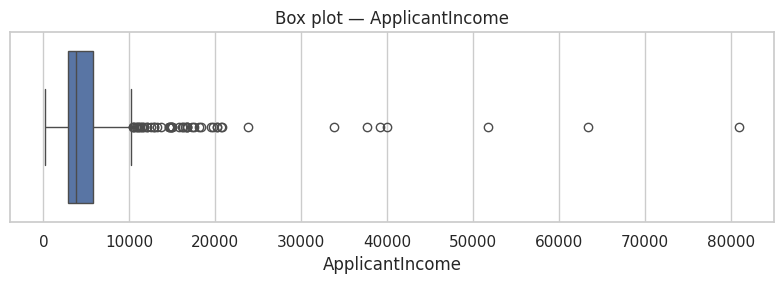

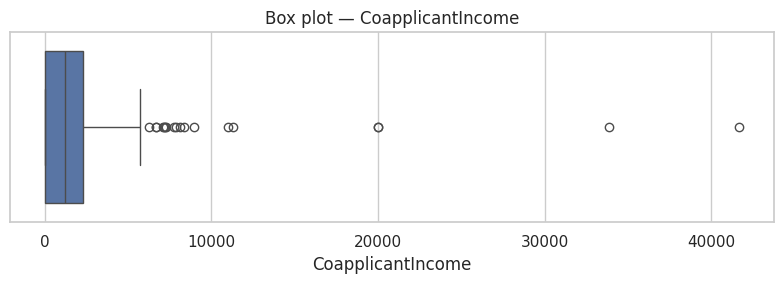

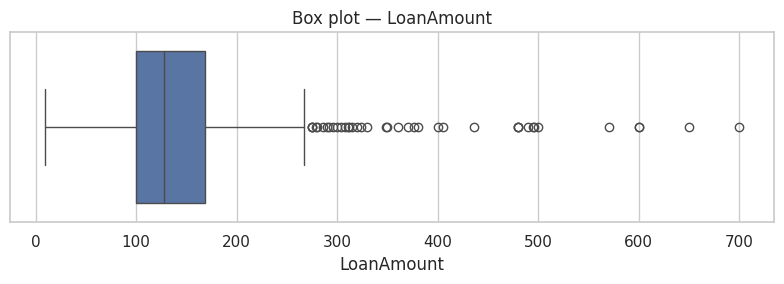

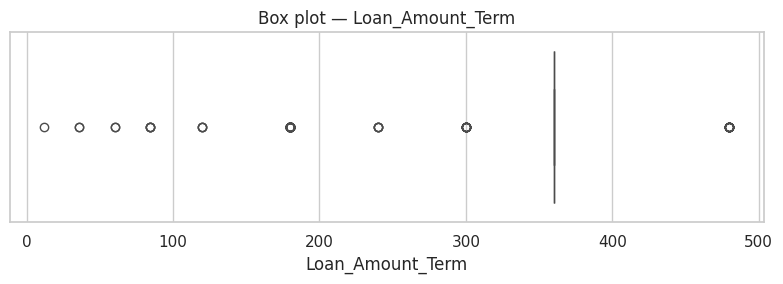

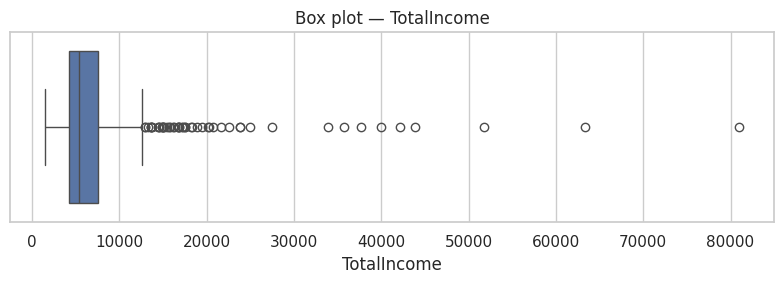

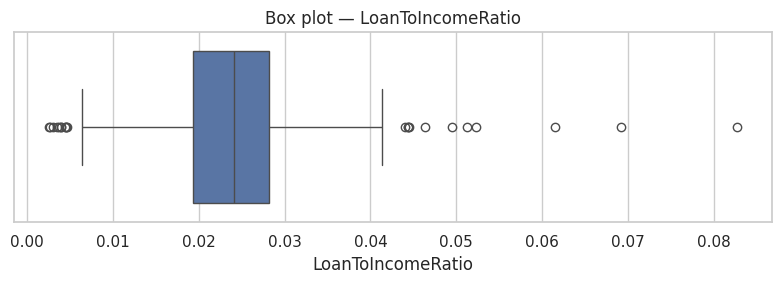

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
# Exclude binary credit history from the continuous-variable outlier plots.
continuous_cols = [c for c in numeric_cols if c != "Credit_History"]

if continuous_cols:
    display(df[continuous_cols].describe().T)
    for col in continuous_cols:
        plt.figure(figsize=(8, 3))
        sns.boxplot(x=df[col])
        plt.title(f"Box plot — {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No continuous numeric columns found.")

In [12]:
outlier_rows = []
for col in continuous_cols:
    series = df[col].dropna()
    if len(series) == 0:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({
        "column": col, "lower_IQR_bound": lower,
        "upper_IQR_bound": upper, "possible_outlier_count": count
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
print("Note: an outlier is not automatically an error. Investigate before changing or removing it.")

,column,lower_IQR_bound,upper_IQR_bound,possible_outlier_count
0,ApplicantIncome,-1498.750000,10171.250000,50
1,CoapplicantIncome,-3445.875000,5743.125000,18
2,LoanAmount,-2.000000,270.000000,39
3,Loan_Amount_Term,360.000000,360.000000,88
4,TotalIncome,-867.625000,12555.375000,50
5,LoanToIncomeRatio,0.006061,0.041401,22


Note: an outlier is not automatically an error. Investigate before changing or removing it.


## Exploratory Data Analysis (EDA)

We perform extensive visual inspections to understand distributions, relationships between attributes, and target correlations.

Target distribution:


,count
Loan_Status,
Y,422
N,192


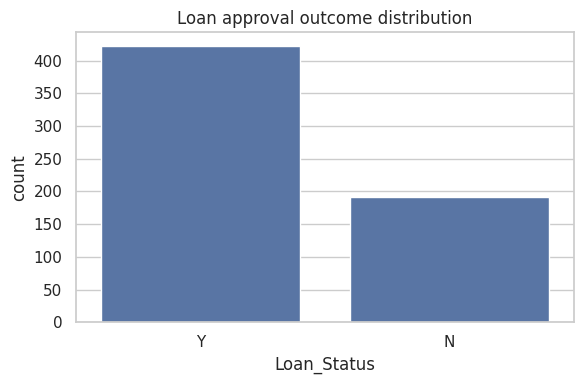

In [13]:
# Target distribution
print("Target distribution:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Loan approval outcome distribution")
plt.tight_layout()
plt.show()

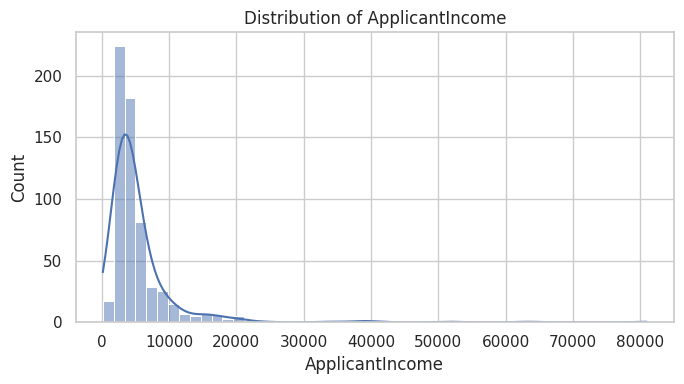

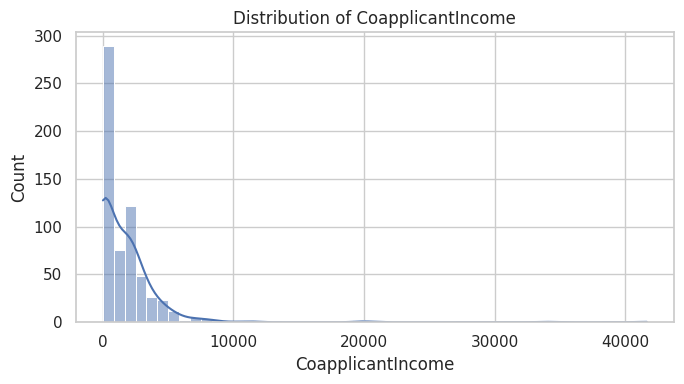

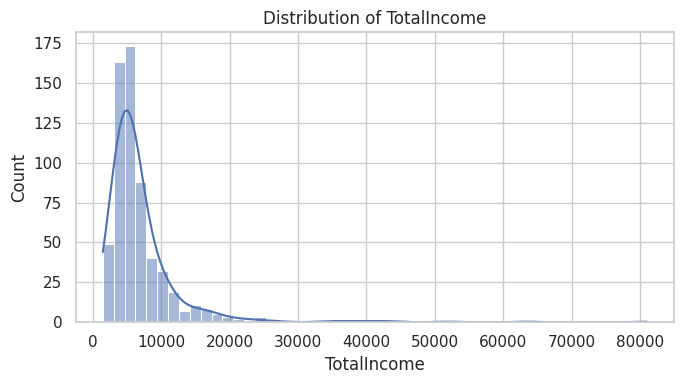

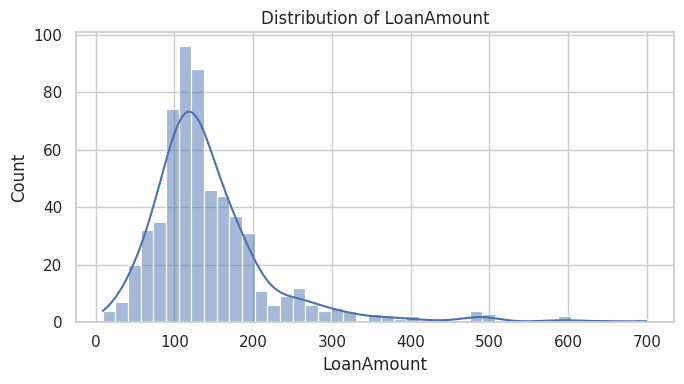

In [14]:
# Numeric distributions
for col in [c for c in ["ApplicantIncome", "CoapplicantIncome", "TotalIncome", "LoanAmount"] if c in df.columns]:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

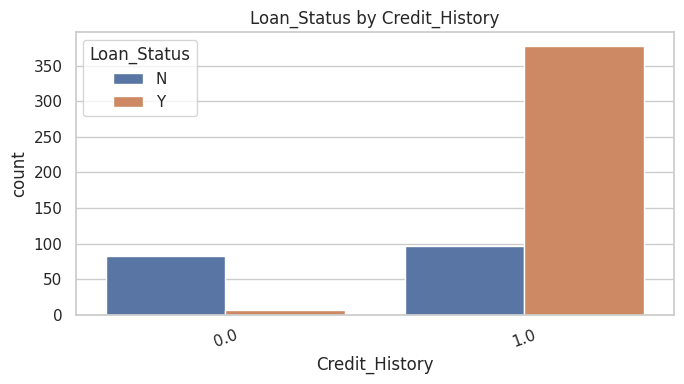

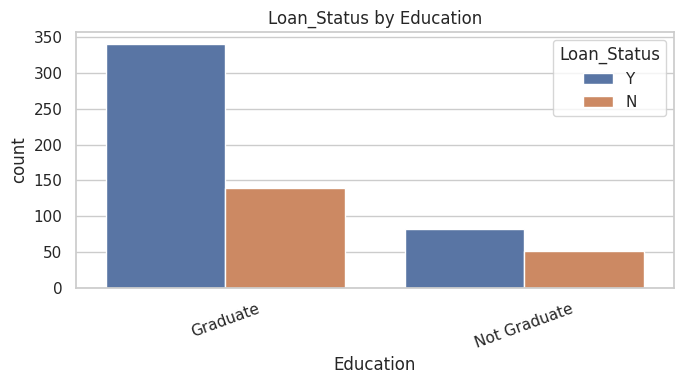

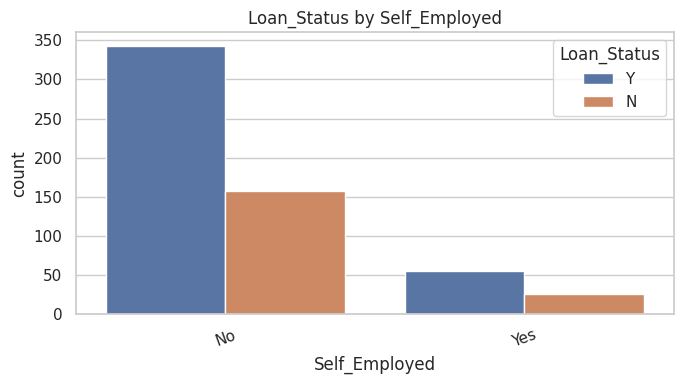

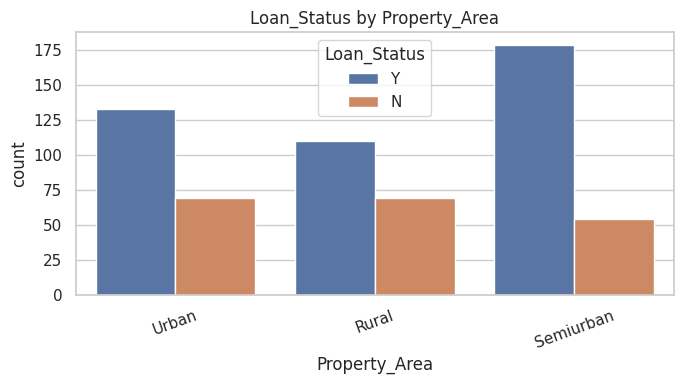

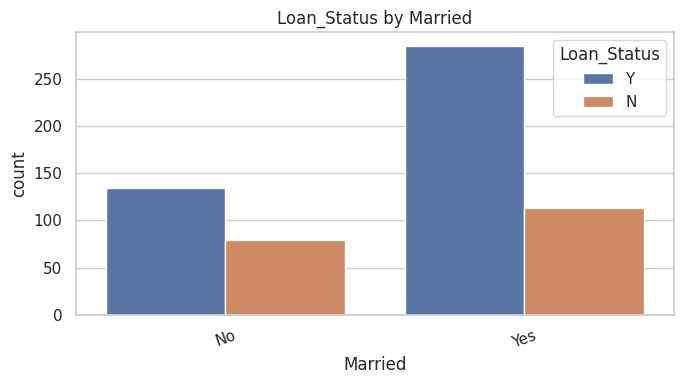

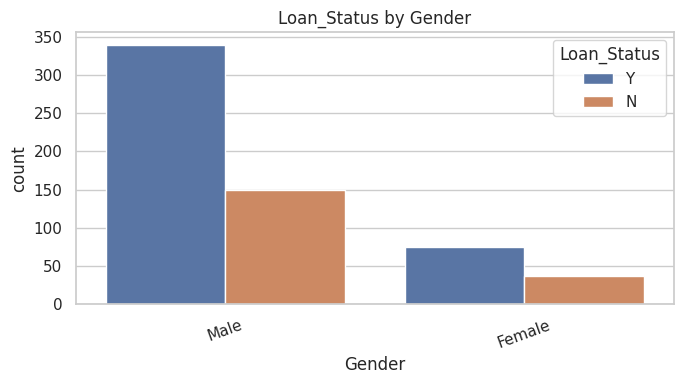

In [15]:
# Approval against important categorical/numeric indicators
for col in ["Credit_History", "Education", "Self_Employed", "Property_Area", "Married", "Gender"]:
    if col in df.columns:
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df, x=col, hue=TARGET)
        plt.title(f"{TARGET} by {col}")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()

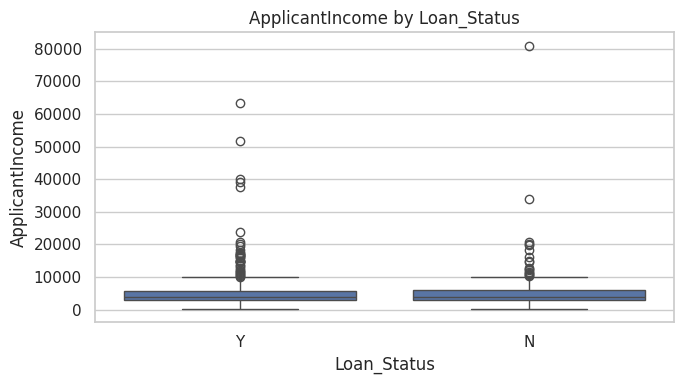

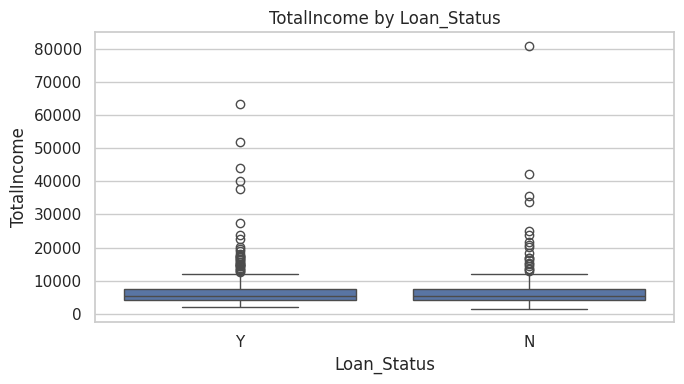

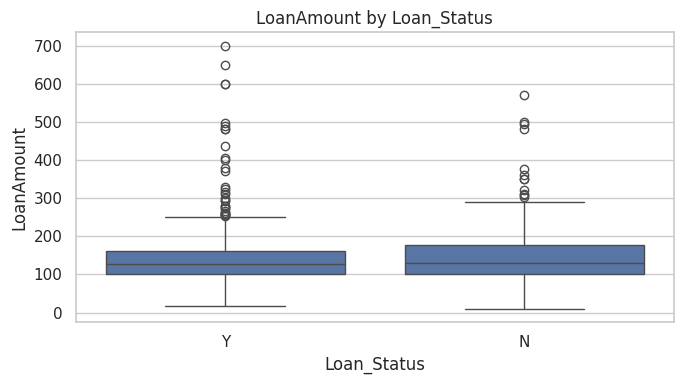

In [16]:
# Numeric variable by outcome
for col in [c for c in ["ApplicantIncome", "TotalIncome", "LoanAmount"] if c in df.columns]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(f"{col} by {TARGET}")
    plt.tight_layout()
    plt.show()

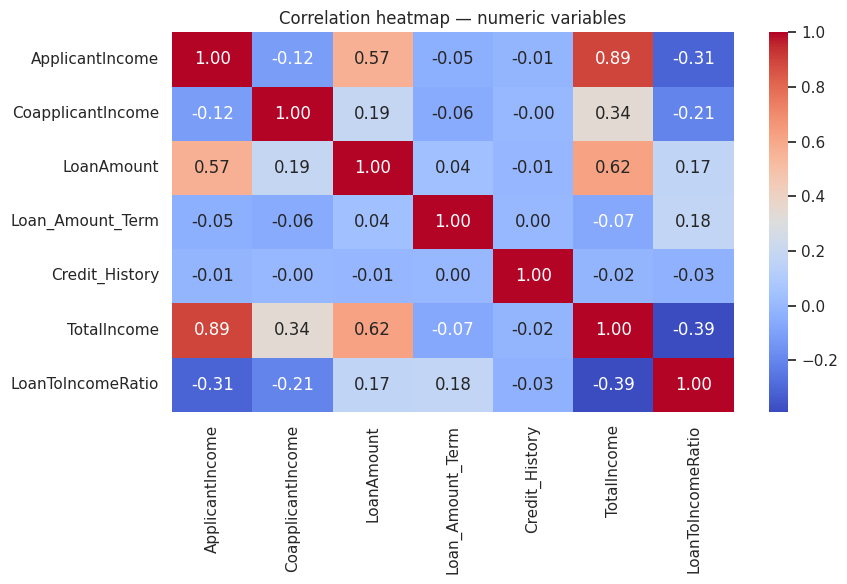

In [17]:
# Correlation heatmap for numeric columns
if len(numeric_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[numeric_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation heatmap — numeric variables")
    plt.tight_layout()
    plt.show()

## Statistical Analysis & Hypothesis Testing

We apply formal statistical inference to validate observations:
1. **Welch's Independent t-test**: Verifies if the mean applicant income differs significantly across loan status groups.
2. **Chi-square Test of Independence**: Examines the relationship between credit history and loan approval outcomes.

In [18]:
# Grouped summaries
for col in [c for c in ["Credit_History", "Education", "Property_Area"] if c in df.columns]:
    print(f"Approval distribution grouped by {col}")
    display(pd.crosstab(df[col], df[TARGET], normalize="index").round(3))

Approval distribution grouped by Credit_History


Loan_Status,N,Y
Credit_History,,
0.0,0.921,0.079
1.0,0.204,0.796


Approval distribution grouped by Education


Loan_Status,N,Y
Education,,
Graduate,0.292,0.708
Not Graduate,0.388,0.612


Approval distribution grouped by Property_Area


Loan_Status,N,Y
Property_Area,,
Rural,0.385,0.615
Semiurban,0.232,0.768
Urban,0.342,0.658


In [19]:
# Example question: Is mean ApplicantIncome different for approved vs not-approved records?
if "ApplicantIncome" in df.columns:
    approved_labels = ["Y", "Yes", "1", 1]
    rejected_labels = ["N", "No", "0", 0]

    approved = df.loc[df[TARGET].isin(approved_labels), "ApplicantIncome"].dropna()
    rejected = df.loc[df[TARGET].isin(rejected_labels), "ApplicantIncome"].dropna()

    if len(approved) >= 2 and len(rejected) >= 2:
        # Welch's independent t-test does not assume equal group variances.
        t_stat, p_value = stats.ttest_ind(approved, rejected, equal_var=False)
        print("H0: Mean ApplicantIncome is equal in approved and rejected groups.")
        print("H1: Mean ApplicantIncome differs between the two groups.")
        print("Welch t-statistic:", round(t_stat, 4))
        print("p-value:", round(p_value, 6))
        print("Decision at 0.05:", "Reject H0" if p_value < 0.05 else "Do not reject H0")
    else:
        print("Could not run t-test: target labels or group sizes were not recognized.")

H0: Mean ApplicantIncome is equal in approved and rejected groups.
H1: Mean ApplicantIncome differs between the two groups.
Welch t-statistic: -0.1094
p-value: 0.912915
Decision at 0.05: Do not reject H0


In [20]:
# Example categorical test: Is Credit_History associated with Loan_Status?
if "Credit_History" in df.columns:
    contingency = pd.crosstab(df["Credit_History"], df[TARGET])
    if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
        chi2, p_value, dof, expected = chi2_contingency(contingency)
        print("H0: Credit_History and Loan_Status are independent.")
        print("H1: Credit_History and Loan_Status are associated.")
        print("Chi-square statistic:", round(chi2, 4))
        print("Degrees of freedom:", dof)
        print("p-value:", round(p_value, 6))
        print("Decision at 0.05:", "Reject H0" if p_value < 0.05 else "Do not reject H0")
        display(contingency)
    else:
        print("Could not run chi-square test: table needs at least 2 rows and 2 columns.")

H0: Credit_History and Loan_Status are independent.
H1: Credit_History and Loan_Status are associated.
Chi-square statistic: 174.6373
Degrees of freedom: 1
p-value: 0.0
Decision at 0.05: Reject H0


Loan_Status,N,Y
Credit_History,,
0.0,82,7
1.0,97,378


## Data Preprocessing

We design a robust scikit-learn preprocessing pipeline using `ColumnTransformer`. It splits data into training and test sets, handles missing values, scales numerical features, and encodes categorical columns.

In [21]:
# Target and input features
y = df[TARGET].copy()

# Remove target and identifier columns from X.
drop_from_X = [TARGET] + identifier_cols
X = df.drop(columns=drop_from_X, errors="ignore").copy()

# Identify numeric and categorical feature columns.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Target:", TARGET)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Target: Loan_Status
Numeric features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome', 'LoanToIncomeRatio']
Categorical features: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [22]:
# Import required libraries
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate input features and target
X = df.drop(
    columns=[TARGET] + identifier_cols,
    errors="ignore"
).copy()

y = df[TARGET].copy()

# Remove rows where target value is missing
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Convert numeric columns to standard float format
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

# Convert categorical columns to object format
# Replace Pandas NA with NumPy NaN
for col in categorical_features:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(X[col].notna(), np.nan)

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_prepared = preprocessor.transform(X_test)

# Display results
print("Training data after preprocessing:", X_train_prepared.shape)
print("Testing data after preprocessing:", X_test_prepared.shape)
print("No ML model has been trained.")

Training data after preprocessing: (491, 22)
Testing data after preprocessing: (123, 22)
No ML model has been trained.


In [23]:
os.makedirs("level1_outputs", exist_ok=True)

df.to_csv("level1_outputs/cleaned_loan_dataset.csv", index=False)
data_dictionary.to_csv("level1_outputs/data_dictionary.csv", index=False)
missing.to_csv("level1_outputs/missing_values_report.csv")
outlier_report.to_csv("level1_outputs/outlier_report.csv", index=False)

# Save the fitted preprocessing transformer for reproducibility.
import joblib
joblib.dump(preprocessor, "level1_outputs/preprocessor.joblib")

print("Saved files in level1_outputs/")
print(os.listdir("level1_outputs"))

Saved files in level1_outputs/
['preprocessor.joblib', 'missing_values_report.csv', 'cleaned_loan_dataset.csv', 'outlier_report.csv', 'data_dictionary.csv']


In [24]:
# Download the output folder as a ZIP file to your computer.
import shutil
shutil.make_archive("loan_approval_level1_outputs", "zip", "level1_outputs")

from google.colab import files
files.download("loan_approval_level1_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Observations

### Key Takeaways:
* **High Predictor Signal**: Credit history has a strong statistical association with loan approval.
* **Pipeline Integrity**: The `ColumnTransformer` successfully structures numerical and categorical variables into model-ready features without data leakage.
* **Academic Readiness**: The dataset is cleaned, structured, and saved with complete traceability for the next phase of modeling.